In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

df = pd.read_csv("data.csv")

#removed duplicates
df = df.drop_duplicates()

print (df.describe())

        Postal Code         Sales     Quantity     Discount      Profit
count   9977.000000   9977.000000  9977.000000  9977.000000  9977.00000
mean   55154.964117    230.148902     3.790719     0.156278    28.69013
std    32058.266816    623.721409     2.226657     0.206455   234.45784
min     1040.000000      0.444000     1.000000     0.000000 -6599.97800
25%    23223.000000     17.300000     2.000000     0.000000     1.72620
50%    55901.000000     54.816000     3.000000     0.200000     8.67100
75%    90008.000000    209.970000     5.000000     0.200000    29.37200
max    99301.000000  22638.480000    14.000000     0.800000  8399.97600


In [2]:
total_sales = df['Sales'].sum()
print (total_sales)
print (df['Sales'].mean())
print (df['Quantity'].sum())

print (df['Profit'].sum())

2296195.5903
230.14890150345792
37820
286241.42260000005


           Ship Mode      Segment        Country          City  \
7772  Standard Class     Consumer  United States     Lancaster   
683         Same Day    Corporate  United States    Burlington   
9774  Standard Class     Consumer  United States   San Antonio   
3011  Standard Class  Home Office  United States    Louisville   
4991  Standard Class    Corporate  United States       Chicago   
3151     First Class     Consumer  United States        Newark   
5310     First Class     Consumer  United States       Houston   
9639    Second Class     Consumer  United States       Concord   
1199  Standard Class     Consumer  United States       Houston   
2697  Standard Class  Home Office  United States  Jacksonville   

               State  Postal Code   Region         Category Sub-Category  \
7772            Ohio        43130     East       Technology     Machines   
683   North Carolina        27217    South       Technology     Machines   
9774           Texas        78207  Central  O

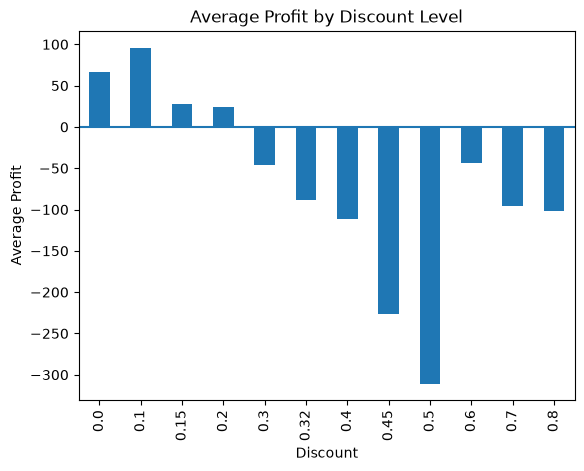

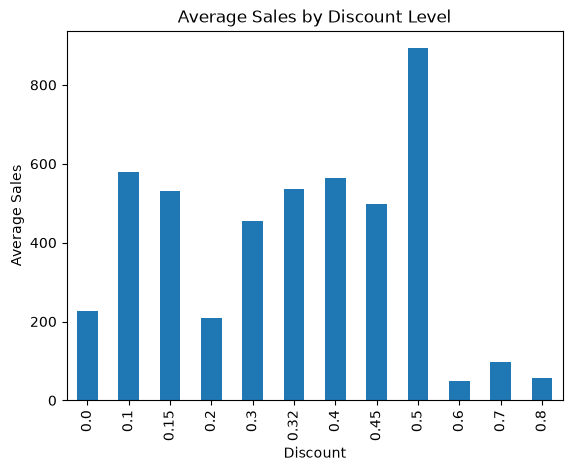

In [6]:
worst_orders = (
    df
    .sort_values("Profit", ascending=True)
    .head(10)
)
print(worst_orders)

discount_profit = (
    df.groupby("Discount")["Profit"]
      .mean()
      .sort_index()
)

discount_profit.plot(kind="bar")

plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.title("Average Profit by Discount Level")
plt.axhline(0)
plt.show()

discount_sales = (
    df.groupby("Discount")["Sales"]
      .mean()
      .sort_index()
)

discount_sales.plot(kind="bar")

plt.xlabel("Discount")
plt.ylabel("Average Sales")
plt.title("Average Sales by Discount Level")

plt.show()

Profit loss - 
- The largest loss recorded was £6,599.98.
- Many of the biggest losses occurred on orders with 70%–80% discounts.
- The worst-performing orders came from multiple regions, indicating losses are not isolated to a single area.
- Several loss-making orders belonged to the Technology and Office Supplies categories.

Do higher discounts reduce profit?
- Orders with 0%–20% discounts are profitable on average.
- From around 30% discount onwards, average profit becomes negative.
- 50% discounts produce the largest average loss (around -£310).
- Overall, higher discounts are associated with lower profitability.

Do higher discounts increase sales?
- Average sales do not increase consistently as discounts increase.
- The 50% discount has the highest average sales value.
- However, discounts of 60%, 70%, and 80% have much lower average sales.
- Therefore, there is no clear evidence that offering larger discounts consistently increases sales.

Although some discount levels (particularly 50%) are associated with higher average sales, the relationship is inconsistent. In contrast, average profit decreases significantly as discount levels increase. This suggests that offering large discounts reduces profitability without consistently increasing sales.

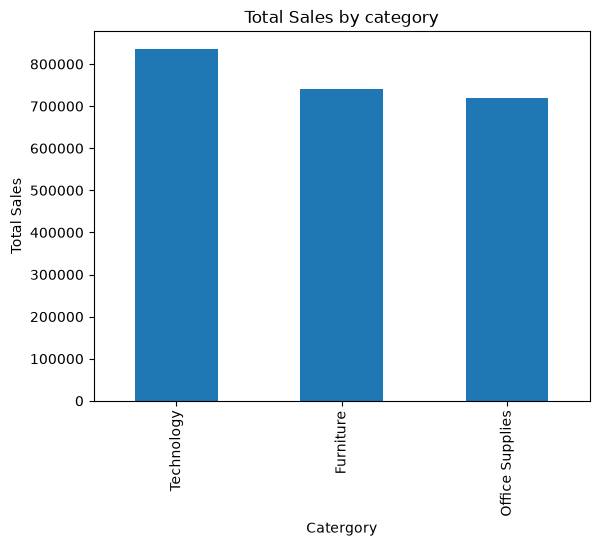

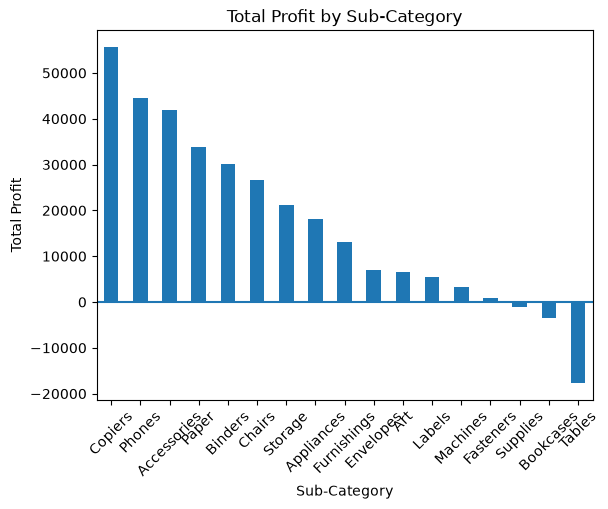

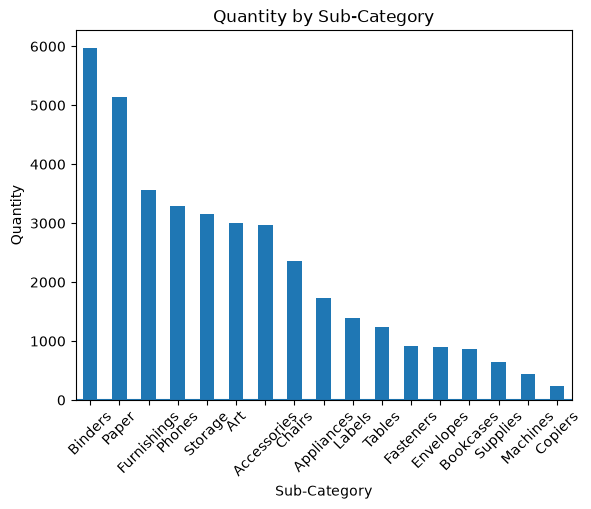

In [7]:
#Catergory sales
category_sales = (
    df.groupby("Category")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

category_sales.plot(kind="bar")

plt.xlabel("Catergory")
plt.ylabel("Total Sales")
plt.title("Total Sales by category")
plt.show()


# Sub_cat profit
sub_category_profit = (
    df.groupby("Sub-Category")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

sub_category_profit.plot(kind="bar")

plt.xlabel("Sub-Category")
plt.ylabel("Total Profit")
plt.title("Total Profit by Sub-Category")
plt.axhline(0)
plt.xticks(rotation=45)
plt.show()


# Sub_cat Quant
sub_category_quantity = (
    df.groupby("Sub-Category")["Quantity"]
      .sum()
      .sort_values(ascending=False)
)


sub_category_quantity.plot(kind="bar")

plt.xlabel("Sub-Category")
plt.ylabel("Quantity")
plt.title("Quantity by Sub-Category")
plt.axhline(0)
plt.xticks(rotation=45)
plt.show()

Which categories generate the most revenue?
- Technology generated the highest total sales.
- Furniture generated the second-highest sales.
- Office Supplies generated the lowest sales of the three categories.
- Although the difference is not huge, Technology is the strongest revenue-generating category.

Which sub-categories perform best in terms of profit?
- Copiers generated the highest total profit.
- Phones and Accessories were also highly profitable.
- Tables generated a significant overall loss, making them the worst-performing sub-category.
- Bookcases and Supplies also produced negative total profits.
- This suggests that some high-selling sub-categories are not necessarily profitable.

categories sell the most units?
- Binders sold the highest number of units.
- Paper and Furnishings were also among the most frequently purchased products.
- Copiers sold the fewest units despite being the most profitable.
- This indicates that selling more units does not necessarily result in higher profits.

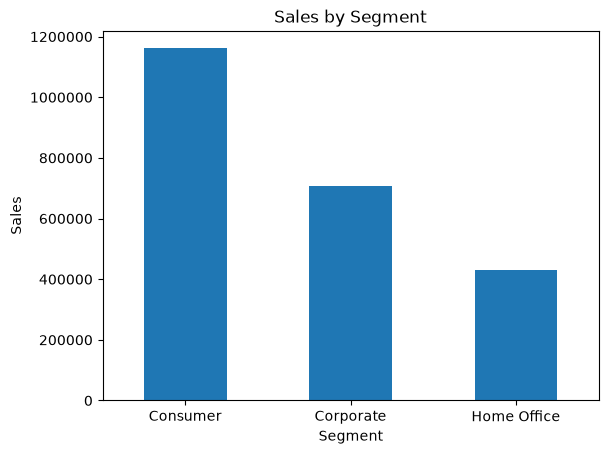

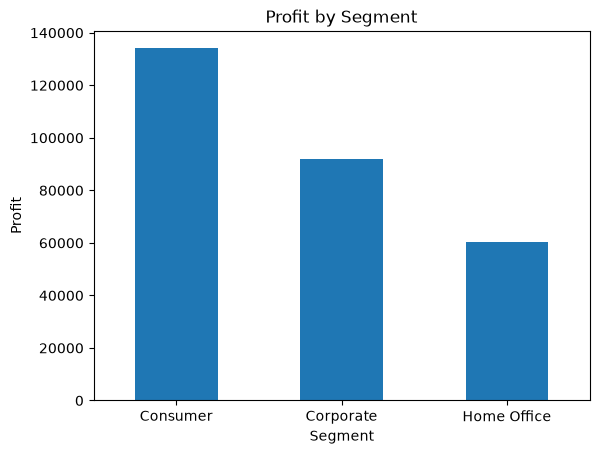

In [8]:
#segment by sales

segment_sales = (
    df.groupby("Segment")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

ax = segment_sales.plot(kind="bar")

ax.ticklabel_format(style="plain", axis="y")

plt.xlabel("Segment")
plt.ylabel("Sales")
plt.title("Sales by Segment")
plt.xticks(rotation=0)
plt.show()

#Which segment is the most profitable?

segment_profits = (
    df.groupby("Segment")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

ax = segment_profits.plot(kind="bar")

ax.ticklabel_format(style="plain", axis="y")

plt.xlabel("Segment")
plt.ylabel("Profit")
plt.title("Profit by Segment")
plt.xticks(rotation=0)
plt.show()

Which customer segment spends the most?
- Consumer customers generated the highest total sales.
- Corporate customers generated the second-highest sales.
- Home Office customers generated the lowest total sales.
- The Consumer segment appears to be the company's largest source of revenue.

Which customer segment is the most profitable?
- Consumer customers generated the highest total profit.
- Corporate customers generated the second-highest profit.
- Home Office customers generated the lowest profit.
- The ranking for profit matches the ranking for sales, suggesting that the Consumer segment is both the highest-spending and the most profitable customer group.

The Consumer segment is the company's strongest customer group, generating both the highest sales and the highest profit. Corporate customers also contribute significantly, while the Home Office segment contributes the least to both revenue and profitability. This suggests that maintaining strong relationships with Consumer customers should remain a key business priority.

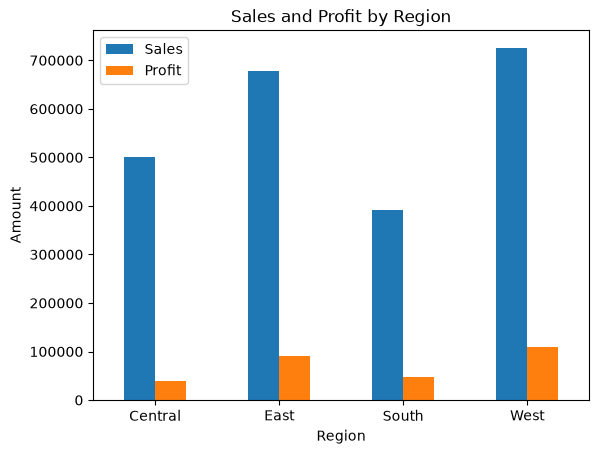

In [11]:
region_sales = df.groupby("Region")["Sales"].sum()

region_profit = df.groupby("Region")["Profit"].sum()

region_summary = df.groupby("Region")[["Sales", "Profit"]].sum()

region_summary.plot(kind="bar")

plt.xlabel("Region")
plt.ylabel("Amount")
plt.title("Sales and Profit by Region")

plt.xticks(rotation=0)

plt.show()

Which region generates the most revenue and profit?
- The West region generates the highest sales (around £725,000) and the highest profit (around £110,000).
- The East region is the second-best performing region for both sales and profit.
- The Central region generates moderate sales but has noticeably lower profit than the East and West.
- The South region has the lowest sales and the second-lowest profit.

The West region is the strongest performing region, leading in both revenue and profitability. The East region also performs well, while the Central and South regions may benefit from targeted strategies such as improved marketing, pricing, or product selection to increase both sales and profit.